### Task 1: Generate polynomial features for mobile phone prices

In [1]:
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures

# Mobile phone dataset
data = {
    "RAM": [4, 6, 8, 12, 16],
    "Storage": [64, 128, 128, 256, 512]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

# Apply Polynomial Features
poly = PolynomialFeatures(degree=2)

poly_features = poly.fit_transform(df)

# Display feature names
feature_names = poly.get_feature_names_out(["RAM", "Storage"])

# Create transformed DataFrame
poly_df = pd.DataFrame(poly_features, columns=feature_names)

print("\nPolynomial Features:")
print(poly_df)

Original Dataset:
   RAM  Storage
0    4       64
1    6      128
2    8      128
3   12      256
4   16      512

Polynomial Features:
     1   RAM  Storage  RAM^2  RAM Storage  Storage^2
0  1.0   4.0     64.0   16.0        256.0     4096.0
1  1.0   6.0    128.0   36.0        768.0    16384.0
2  1.0   8.0    128.0   64.0       1024.0    16384.0
3  1.0  12.0    256.0  144.0       3072.0    65536.0
4  1.0  16.0    512.0  256.0       8192.0   262144.0


### Task 2: Compare Linear and Polynomial Regression for Zomato ratings

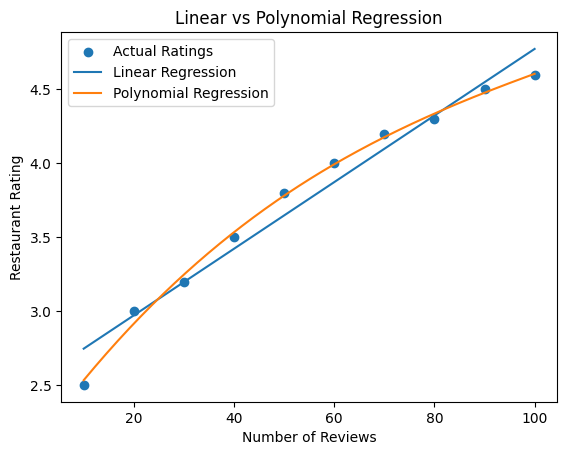

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# Number of reviews
X = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100]).reshape(-1, 1)

# Restaurant ratings
y = np.array([2.5, 3.0, 3.2, 3.5, 3.8, 4.0, 4.2, 4.3, 4.5, 4.6])

# Linear Regression Model
linear_model = LinearRegression()
linear_model.fit(X, y)

# Polynomial Regression Model (Degree 3)
poly_model = make_pipeline(
    PolynomialFeatures(degree=3),
    LinearRegression()
)

poly_model.fit(X, y)

# Generate smooth values for plotting
X_plot = np.linspace(10, 100, 200).reshape(-1, 1)

# Predictions
linear_predictions = linear_model.predict(X_plot)
poly_predictions = poly_model.predict(X_plot)

# Plot both models
plt.scatter(X, y, label="Actual Ratings")
plt.plot(X_plot, linear_predictions, label="Linear Regression")
plt.plot(X_plot, poly_predictions, label="Polynomial Regression")

plt.xlabel("Number of Reviews")
plt.ylabel("Restaurant Rating")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.show()

### Task 3: Check overfitting using polynomial degrees 1 to 5

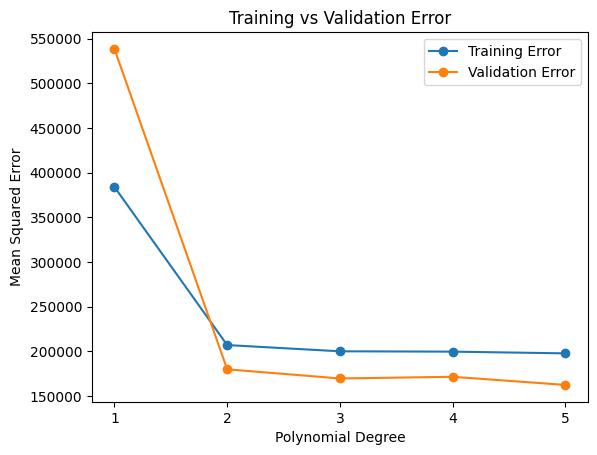

Degree 4 Model Training MSE: 199498.00536736796
Degree 4 Model Validation MSE: 171323.68375853775


In [4]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# Create sample Instagram data
np.random.seed(42)

posts = np.arange(1, 51)
followers = 100 + 20 * posts + 2 * (posts ** 2) + np.random.normal(0, 500, 50)

X = posts.reshape(-1, 1)
y = followers

# Split into training and validation data
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

train_errors = []
validation_errors = []

# Test polynomial degrees from 1 to 5
degrees = range(1, 6)

for degree in degrees:

    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    val_predictions = model.predict(X_val)

    train_mse = mean_squared_error(y_train, train_predictions)
    val_mse = mean_squared_error(y_val, val_predictions)

    train_errors.append(train_mse)
    validation_errors.append(val_mse)

# Plot training and validation errors
plt.plot(degrees, train_errors, marker="o", label="Training Error")
plt.plot(degrees, validation_errors, marker="o", label="Validation Error")

plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title("Training vs Validation Error")
plt.xticks(list(degrees))
plt.legend()
plt.show()

# Train the final degree 4 model
degree4_model = make_pipeline(
    PolynomialFeatures(degree=4),
    LinearRegression()
)

degree4_model.fit(X_train, y_train)

print("Degree 4 Model Training MSE:",
      mean_squared_error(y_train, degree4_model.predict(X_train)))

print("Degree 4 Model Validation MSE:",
      mean_squared_error(y_val, degree4_model.predict(X_val)))

### Task 4: Apply Ridge Regression to Flipkart product prices

In [5]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

# Sample Flipkart product dataset
data = {
    "RAM": [4, 6, 8, 12, 16, 4, 8, 12, 16, 6,
            8, 12, 16, 4, 6, 8, 12, 16, 4, 8],
    "Storage": [64, 128, 128, 256, 512, 64, 256, 256, 512, 128,
                128, 512, 256, 128, 256, 512, 128, 256, 256, 512],
    "Price": [8000, 12000, 16000, 25000, 40000, 8500, 19000,
              27000, 42000, 13000, 17000, 30000, 38000, 9000,
              15000, 23000, 26000, 41000, 11000, 24000]
}

df = pd.DataFrame(data)

# Features and target
X = df[["RAM", "Storage"]]
y = df["Price"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Model 1: Polynomial Regression without regularization
model_without_ridge = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    StandardScaler(),
    LinearRegression()
)

model_without_ridge.fit(X_train, y_train)

# Model 2: Polynomial Regression with Ridge
model_with_ridge = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    StandardScaler(),
    Ridge(alpha=1.0)
)

model_with_ridge.fit(X_train, y_train)

# Predictions
pred_without_ridge = model_without_ridge.predict(X_test)
pred_with_ridge = model_with_ridge.predict(X_test)

# Evaluation function
def evaluate_model(actual, predicted):

    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    print("MSE:", round(mse, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 2))


print("WITHOUT RIDGE REGRESSION")
evaluate_model(y_test, pred_without_ridge)

print("\nWITH RIDGE REGRESSION")
evaluate_model(y_test, pred_with_ridge)

WITHOUT RIDGE REGRESSION
MSE: 2475370.08
RMSE: 1573.33
R2 Score: 0.98

WITH RIDGE REGRESSION
MSE: 4913449.68
RMSE: 2216.63
R2 Score: 0.97


### Task 5: Demonstrate underfitting and overfitting using Polynomial Regression

Polynomial Degree: 1
Training MSE: 38.08
Testing MSE: 66.82

Polynomial Degree: 4
Training MSE: 5.95
Testing MSE: 12.56

Polynomial Degree: 15
Training MSE: 1.65
Testing MSE: 250.51



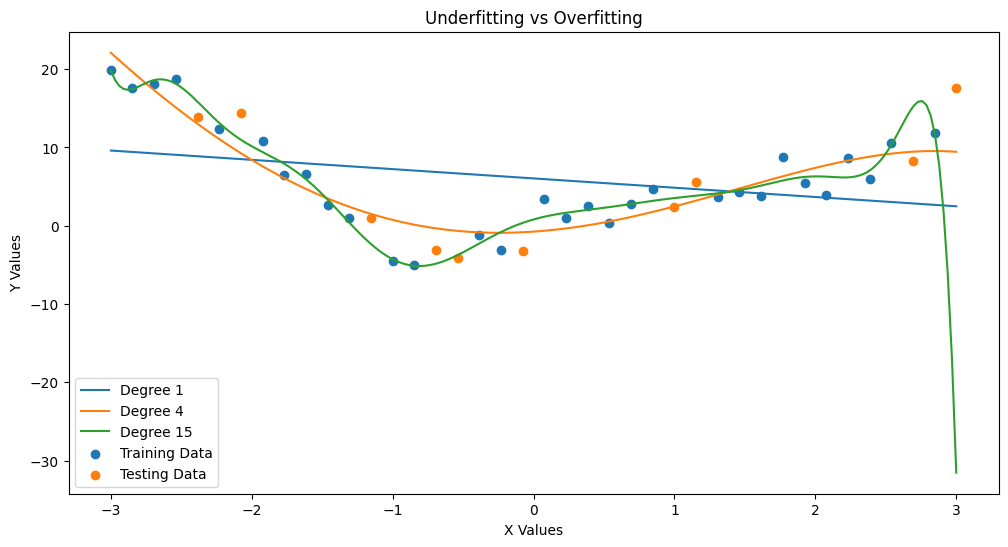

In [6]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# Create synthetic dataset
np.random.seed(42)

X = np.linspace(-3, 3, 40).reshape(-1, 1)

y = 2 * X.ravel() ** 2 + 3 * np.sin(2 * X.ravel())
y = y + np.random.normal(0, 2, 40)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Values for smooth graph
X_plot = np.linspace(-3, 3, 200).reshape(-1, 1)

# Polynomial degrees
degrees = [1, 4, 15]

plt.figure(figsize=(12, 6))

for degree in degrees:

    # Create model
    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    # Train model
    model.fit(X_train, y_train)

    # Predictions
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)
    plot_predictions = model.predict(X_plot)

    # Calculate errors
    train_mse = mean_squared_error(y_train, train_predictions)
    test_mse = mean_squared_error(y_test, test_predictions)

    print("Polynomial Degree:", degree)
    print("Training MSE:", round(train_mse, 2))
    print("Testing MSE:", round(test_mse, 2))
    print()

    # Plot model
    plt.plot(X_plot, plot_predictions, label=f"Degree {degree}")

# Plot actual data
plt.scatter(X_train, y_train, label="Training Data")
plt.scatter(X_test, y_test, label="Testing Data")

plt.xlabel("X Values")
plt.ylabel("Y Values")
plt.title("Underfitting vs Overfitting")
plt.legend()
plt.show()